**Connecting to the drive**

In [1]:
from google.colab import drive
from pathlib import Path
import json, os, random
import numpy as np
import pandas as pd
import tensorflow as tf

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Set the drive paths
PROJECT_DIR = Path('/content/drive/MyDrive/Research/Model_Training')
IMAGE_DIR = PROJECT_DIR / 'Images'
MANIFEST_DIR = PROJECT_DIR / 'private_manifests' / 'components'

assert PROJECT_DIR.exists(), f'Project folder not found: {PROJECT_DIR}'
assert IMAGE_DIR.exists(), f'Image folder not found: {IMAGE_DIR}'
assert MANIFEST_DIR.exists(), f'Manifest folder not found: {MANIFEST_DIR}'

In [3]:
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 16
EPOCHS_FROZEN = 15
EPOCHS_FINE_TUNE = 8
SEED = 42
USE_CLASS_WEIGHTS = True
USE_HORIZONTAL_FLIP = False

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('Images:', IMAGE_DIR)
print('Manifest folder:', MANIFEST_DIR)

Images: /content/drive/MyDrive/Research/Model_Training/Images
Manifest folder: /content/drive/MyDrive/Research/Model_Training/private_manifests/components


In [4]:
# This selects my OLP task, manifest and MobileNetV2 backbone
TASK = 'olp'
TASK_MODE = 'binary'
NUM_CLASSES = 2
CLASS_NAMES = ['negative', 'positive']
MODEL_NAME = 'MobileNetV2'
APP = tf.keras.applications.MobileNetV2
PREPROCESS = tf.keras.applications.mobilenet_v2.preprocess_input
CSV_PATH = MANIFEST_DIR / 'olp.csv'
OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'olp_MobileNetV2'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert CSV_PATH.is_file(), f'Manifest not found: {CSV_PATH}'

In [5]:
# This loads the supplied patient-level split so each patient stays in the assigned group
df = pd.read_csv(CSV_PATH)
required = {'image_id', 'patient_id', 'target', 'split'}
missing = required - set(df.columns)
assert not missing, f'Missing columns: {missing}'

df['target'] = df['target'].astype(int)
expected_targets = set(range(NUM_CLASSES))
assert set(df['target'].unique()).issubset(expected_targets), f'target values must be within {expected_targets}'
assert set(df['split'].unique()).issubset({'train', 'validation', 'test'})

split_per_patient = df.groupby('patient_id')['split'].nunique()
leaking_patients = split_per_patient[split_per_patient > 1]
assert len(leaking_patients) == 0, f'Patient leakage found: {list(leaking_patients.index)}'

print('Rows:', len(df))
print('Patients:', df['patient_id'].nunique())
for split_name in ['train', 'validation', 'test']:
    part = df[df['split'] == split_name]
    print(f'{split_name}: {len(part)} images / {part["patient_id"].nunique()} patients')
    for class_id, class_name in enumerate(CLASS_NAMES):
        class_rows = part[part['target'] == class_id]
        print(f'  {class_id} {class_name}: {len(class_rows)} images / '
              f'{class_rows["patient_id"].nunique()} patients')

assert (df['split'] == 'train').any(), 'No training rows'
assert (df['split'] == 'validation').any(), 'No validation rows'
assert (df['split'] == 'test').any(), 'No test rows'
assert df[df['split'] == 'train']['target'].nunique() == NUM_CLASSES, 'Training split must contain every configured class'

Rows: 2999
Patients: 714
train: 2079 images / 500 patients
  0 negative: 1713 images / 443 patients
  1 positive: 366 images / 93 patients
validation: 449 images / 107 patients
  0 negative: 401 images / 97 patients
  1 positive: 48 images / 15 patients
test: 471 images / 107 patients
  0 negative: 370 images / 96 patients
  1 positive: 101 images / 19 patients


In [6]:
# Match CSV image IDs to files and build datasets
from collections import defaultdict

allowed_ext = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
by_name, by_stem = defaultdict(list), defaultdict(list)
for path in IMAGE_DIR.rglob('*'):
    if path.is_file() and path.suffix.lower() in allowed_ext:
        by_name[path.name.casefold()].append(path)
        by_stem[path.stem.casefold()].append(path)

def resolve_image(image_id):
    key = Path(str(image_id)).name.casefold()
    matches = by_name.get(key, [])
    if not matches:
        matches = by_stem.get(Path(key).stem.casefold(), [])
    # This catches image names that map to more than one file extension.
    matches = sorted(set(matches))
    if len(matches) != 1:
        return None, [str(p) for p in matches]
    return str(matches[0]), []

resolved, missing, ambiguous = [], [], []
for image_id in df['image_id']:
    path, choices = resolve_image(image_id)
    resolved.append(path)
    if path is None:
        if choices:
            ambiguous.append((image_id, choices))
        else:
            missing.append(image_id)

if missing or ambiguous:
    print('Missing image IDs (first 20):', missing[:20])
    print('Ambiguous image IDs (first 10):', ambiguous[:10])
    raise ValueError('Fix image paths/names before training; no rows were dropped.')

df['image_path'] = resolved
print(f'Matched {len(df)} manifest rows to image files.')

train_df = df[df['split'] == 'train'].copy()
val_df = df[df['split'] == 'validation'].copy()
test_df = df[df['split'] == 'test'].copy()

AUTOTUNE = tf.data.AUTOTUNE
augment_layers = [
    tf.keras.layers.RandomRotation(0.03, fill_mode='reflect'),
    tf.keras.layers.RandomTranslation(0.02, 0.02, fill_mode='reflect'),
    tf.keras.layers.RandomZoom(0.05, fill_mode='reflect'),
    tf.keras.layers.RandomContrast(0.10),
]
if USE_HORIZONTAL_FLIP:
    augment_layers.insert(0, tf.keras.layers.RandomFlip('horizontal'))
augmentation = tf.keras.Sequential(augment_layers, name='train_only_augmentation')

def make_dataset(frame, training=False):
    paths = frame['image_path'].astype(str).to_numpy()
    labels = frame['target'].astype('int32' if TASK_MODE == 'multiclass' else 'float32').to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)

    def load_and_prepare(path, label):
        raw = tf.io.read_file(path)
        image = tf.io.decode_image(raw, channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.cast(image, tf.float32)
        # This preserves the full image and pads it to a square before resizing.
        image = tf.image.resize_with_pad(image, IMG_HEIGHT, IMG_WIDTH)
        if training:
            # These transformations add training variety while validation and test images stay unchanged.
            image = augmentation(image, training=True)
            image = tf.clip_by_value(image, 0.0, 255.0)
        image = PREPROCESS(image)
        return image, label

    return ds.map(load_and_prepare, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)
print('Datasets ready:', len(train_df), len(val_df), len(test_df))

Matched 2999 manifest rows to image files.
Datasets ready: 2079 449 471


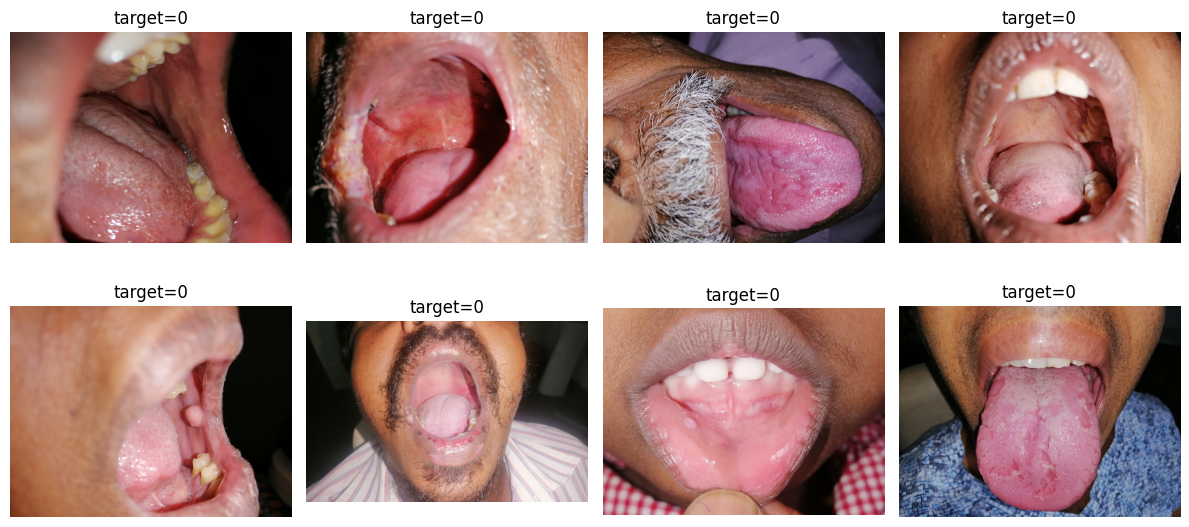

In [7]:
# Visually inspect source images before fitting
import matplotlib.pyplot as plt
from PIL import Image

sample = train_df.sample(min(8, len(train_df)), random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    ax.imshow(Image.open(row['image_path']).convert('RGB'))
    ax.set_title(f"target={row['target']}")
    ax.axis('off')
plt.tight_layout()
plt.show()

In [8]:
#Build the selected pretrained classifier
from tensorflow import keras
from tensorflow.keras import layers

# This builds the single pretrained architecture selected in the member configuration.
base_model = APP(
    include_top=False,
    weights='imagenet',
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
)
base_model.trainable = False

inputs = keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3), name='preprocessed_image')
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
if TASK_MODE == 'multiclass':
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='class_probabilities')(x)
else:
    outputs = layers.Dense(1, activation='sigmoid', name='disease_probability')(x)
model = keras.Model(inputs, outputs, name=f'{TASK}_{MODEL_NAME}')

def compile_model(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=(keras.losses.SparseCategoricalCrossentropy()
              if TASK_MODE == 'multiclass' else keras.losses.BinaryCrossentropy()),
        metrics=([
            keras.metrics.SparseCategoricalAccuracy(name='accuracy'),
        ] if TASK_MODE == 'multiclass' else [
            keras.metrics.BinaryAccuracy(name='accuracy', threshold=0.5),
            keras.metrics.Precision(name='precision', thresholds=0.5),
            keras.metrics.Recall(name='recall', thresholds=0.5),
            keras.metrics.AUC(name='roc_auc'),
            keras.metrics.AUC(name='pr_auc', curve='PR'),
        ]),
    )

compile_model(model, learning_rate=1e-3)
model.summary()

# These weights address training class imbalance; validation and test keep their original class proportions.
counts = np.bincount(train_df['target'].astype(int), minlength=NUM_CLASSES)
assert np.all(counts > 0), f'Every configured class must occur in training: {counts}'
class_weight = {i: len(train_df) / (NUM_CLASSES * counts[i]) for i in range(NUM_CLASSES)}
print('Training class counts by class ID:', counts)
print('Class weights:', class_weight if USE_CLASS_WEIGHTS else 'disabled')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "olp_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ preprocessed_image (InputLayer) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ disease_probability (Dense)     │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Training class counts by class ID: [1713  366]
Class weights: {0: np.float64(0.6068301225919439), 1: np.float64(2.8401639344262297)}


In [9]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, CSVLogger

frozen_path = OUTPUT_DIR / 'best_frozen_model.keras'
common_callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-7),
    CSVLogger(str(OUTPUT_DIR / 'frozen_training_history.csv')),
    ModelCheckpoint(str(frozen_path), monitor='val_loss', save_best_only=True),
]

history_frozen = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FROZEN,
    class_weight=class_weight if USE_CLASS_WEIGHTS else None,
    callbacks=common_callbacks,
)
model_frozen = keras.models.load_model(frozen_path)
val_loss_frozen = model_frozen.evaluate(val_ds, verbose=0)[0]
print('Best frozen validation loss:', val_loss_frozen)

Epoch 1/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 765s 6s/step - accuracy: 0.5416 - loss: 0.7696 - pr_auc: 0.2007 - precision: 0.1977 - recall: 0.5246 - roc_auc: 0.5533 - val_accuracy: 0.7617 - val_loss: 0.5183 - val_pr_auc: 0.2040 - val_precision: 0.2020 - val_recall: 0.4167 - val_roc_auc: 0.6639 - learning_rate: 0.0010
Epoch 2/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 508s 4s/step - accuracy: 0.6171 - loss: 0.6724 - pr_auc: 0.2722 - precision: 0.2637 - recall: 0.6557 - roc_auc: 0.6674 - val_accuracy: 0.7261 - val_loss: 0.5276 - val_pr_auc: 0.2553 - val_precision: 0.2093 - val_recall: 0.5625 - val_roc_auc: 0.7067 - learning_rate: 0.0010
Epoch 3/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 551s 4s/step - accuracy: 0.6676 - loss: 0.6065 - pr_auc: 0.3712 - precision: 0.3026 - recall: 0.6803 - roc_auc: 0.7383 - val_accuracy: 0.7773 - val_loss: 0.4860 - val_pr_auc: 0.2749 - val_precision: 0.2400 - val_recall: 0.5000 - val_roc_auc: 0.7332 - learning_rate: 0.0010
Epoch 4/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 502s 4s/step - accura

In [10]:
# fine-tuning
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

compile_model(model, learning_rate=1e-5)
fine_path = OUTPUT_DIR / 'best_finetuned_model.keras'
fine_callbacks = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-8),
    CSVLogger(str(OUTPUT_DIR / 'finetune_training_history.csv')),
    ModelCheckpoint(str(fine_path), monitor='val_loss', save_best_only=True),
]

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE_TUNE,
    class_weight=class_weight if USE_CLASS_WEIGHTS else None,
    callbacks=fine_callbacks,
)

model_fine = keras.models.load_model(fine_path)
val_loss_fine = model_fine.evaluate(val_ds, verbose=0)[0]
if val_loss_fine < val_loss_frozen:
    final_model = model_fine
    selected_stage = 'fine-tuned'
else:
    final_model = model_frozen
    selected_stage = 'frozen'

final_path = OUTPUT_DIR / 'selected_final_model.keras'
final_model.save(final_path)
print('Selected using validation loss:', selected_stage)
print('Frozen val loss:', val_loss_frozen, '| fine-tuned val loss:', val_loss_fine)
print('Saved:', final_path)

Epoch 1/8
130/130 ━━━━━━━━━━━━━━━━━━━━ 598s 4s/step - accuracy: 0.7239 - loss: 0.5450 - pr_auc: 0.4460 - precision: 0.3587 - recall: 0.7213 - roc_auc: 0.7970 - val_accuracy: 0.7506 - val_loss: 0.5221 - val_pr_auc: 0.2791 - val_precision: 0.2241 - val_recall: 0.5417 - val_roc_auc: 0.7487 - learning_rate: 1.0000e-05
Epoch 2/8
130/130 ━━━━━━━━━━━━━━━━━━━━ 573s 4s/step - accuracy: 0.7186 - loss: 0.5345 - pr_auc: 0.4666 - precision: 0.3565 - recall: 0.7432 - roc_auc: 0.8033 - val_accuracy: 0.7639 - val_loss: 0.4997 - val_pr_auc: 0.2940 - val_precision: 0.2315 - val_recall: 0.5208 - val_roc_auc: 0.7508 - learning_rate: 1.0000e-05
Epoch 3/8
130/130 ━━━━━━━━━━━━━━━━━━━━ 522s 4s/step - accuracy: 0.7379 - loss: 0.4945 - pr_auc: 0.5061 - precision: 0.3802 - recall: 0.7760 - roc_auc: 0.8369 - val_accuracy: 0.7840 - val_loss: 0.4624 - val_pr_auc: 0.2885 - val_precision: 0.2366 - val_recall: 0.4583 - val_roc_auc: 0.7426 - learning_rate: 1.0000e-05
Epoch 4/8
130/130 ━━━━━━━━━━━━━━━━━━━━ 524s 4s/step 

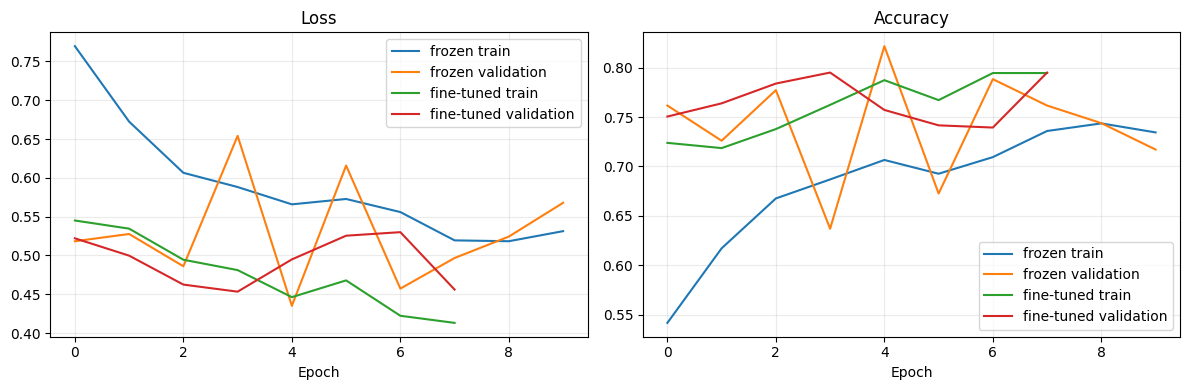

Saved: /content/drive/MyDrive/Research/Model_Training/outputs/olp_MobileNetV2/validation_curves.png


In [11]:
# Save validation curves
import matplotlib.pyplot as plt

histories = [('frozen', history_frozen.history)]
if 'history_fine' in globals():
    histories.append(('fine-tuned', history_fine.history))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for stage, values in histories:
    axes[0].plot(values['loss'], label=f'{stage} train')
    axes[0].plot(values['val_loss'], label=f'{stage} validation')
    if 'accuracy' in values and 'val_accuracy' in values:
        axes[1].plot(values['accuracy'], label=f'{stage} train')
        axes[1].plot(values['val_accuracy'], label=f'{stage} validation')
axes[0].set_title('Loss')
axes[1].set_title('Accuracy')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.legend()
    ax.grid(True, alpha=0.25)
fig.tight_layout()
curve_path = OUTPUT_DIR / 'validation_curves.png'
fig.savefig(curve_path, dpi=160, bbox_inches='tight')
plt.show()
print('Saved:', curve_path)

In [12]:
# Save the experiment configuration and README
split_summary = {}
for split_name, frame in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    positive = frame[frame['target'] == 1]
    split_summary[split_name] = {
        'images': int(len(frame)),
        'patients': int(frame['patient_id'].nunique()),
        'positive_images': int(len(positive)),
        'positive_patients': int(positive['patient_id'].nunique()),
    }

experiment_config = {
    'task': TASK,
    'task_mode': TASK_MODE,
    'class_names': CLASS_NAMES,
    'architecture': MODEL_NAME,
    'pretrained_weights': 'ImageNet',
    'selected_stage': selected_stage,
    'selected_checkpoint': final_path.name,
    'input': {
        'color': 'RGB',
        'height': IMG_HEIGHT,
        'width': IMG_WIDTH,
        'resize': 'tf.image.resize_with_pad',
        'model_preprocessing': PREPROCESS.__name__,
    },
    'augmentation': {
        'rotation_factor': 0.03,
        'translation_height_width': [0.02, 0.02],
        'zoom_factor': 0.05,
        'contrast_factor': 0.10,
        'horizontal_flip': USE_HORIZONTAL_FLIP,
        'training_only': True,
    },
    'class_weights_enabled': USE_CLASS_WEIGHTS,
    'optimizer': 'Adam',
    'frozen_learning_rate': 1e-3,
    'fine_tune_learning_rate': 1e-5,
    'frozen_epochs_requested': EPOCHS_FROZEN,
    'frozen_epochs_completed': len(history_frozen.history['loss']),
    'fine_tune_epochs_requested': EPOCHS_FINE_TUNE,
    'fine_tune_epochs_completed': len(history_fine.history['loss']) if 'history_fine' in globals() else 0,
    'batch_size': BATCH_SIZE,
    'seed': SEED,
    'split_counts': split_summary,
}
with open(OUTPUT_DIR / 'experiment_config.json', 'w') as f:
    json.dump(experiment_config, f, indent=2)
with open(OUTPUT_DIR / 'dataset_split_summary.json', 'w') as f:
    json.dump(split_summary, f, indent=2)

readme = f"""# {TASK} model run

- Architecture: {MODEL_NAME} with ImageNet pretrained weights
- Task mode: {TASK_MODE}; classes: {CLASS_NAMES}
- Selected stage: {selected_stage}
- Saved model: `{final_path.name}`
- Input: RGB, {IMG_HEIGHT}x{IMG_WIDTH}; full image preserved with resize and padding
- Model preprocessing: `{PREPROCESS.__name__}`
- Optimizer: Adam; frozen learning rate 0.001; fine-tuning learning rate 0.00001
- Augmentation: train only; rotation 0.03, translation 0.02, zoom 0.05, contrast 0.10, horizontal flip {USE_HORIZONTAL_FLIP}
- Class weights enabled: {USE_CLASS_WEIGHTS}
- Batch size: {BATCH_SIZE}; seed: {SEED}

See `experiment_config.json` for full settings and split counts, `dataset_split_summary.json` for image/patient counts, and `test_summary.json` for final held-out test metrics. `validation_curves.png` and training-history CSV files contain the training curves and epoch history.
"""
(OUTPUT_DIR / 'README.md').write_text(readme)
print('Saved configuration, split summary and README in:', OUTPUT_DIR)


Saved configuration, split summary and README in: /content/drive/MyDrive/Research/Model_Training/outputs/olp_MobileNetV2
